In [23]:
### Homework 6 Code - Karann Singam - 801285554 ###

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import numpy as np

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_1516/726632306.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace({"no": 0, "yes": 1})
/tmp/ipykernel_1516/726632306.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace({"unfurnished": 0, "semi-furnished": 1, "furnished": 2})


(Epoch = 100) Training Loss = 0.592702, Validation Loss = 0.596314
(Epoch = 200) Training Loss = 0.331365, Validation Loss = 0.352885
(Epoch = 300) Training Loss = 0.307798, Validation Loss = 0.335699
(Epoch = 400) Training Loss = 0.296318, Validation Loss = 0.330657
(Epoch = 500) Training Loss = 0.288591, Validation Loss = 0.328806
(Epoch = 600) Training Loss = 0.282536, Validation Loss = 0.328088
(Epoch = 700) Training Loss = 0.277212, Validation Loss = 0.327185
(Epoch = 800) Training Loss = 0.272240, Validation Loss = 0.327052
(Epoch = 900) Training Loss = 0.267452, Validation Loss = 0.327239
(Epoch = 1000) Training Loss = 0.262734, Validation Loss = 0.327581



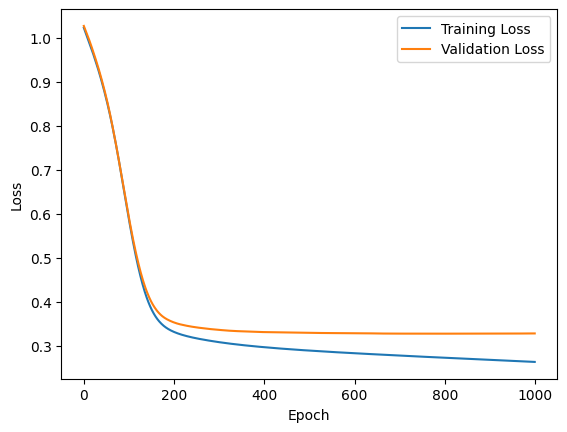


Mean Squared Error = 1139518078976.0
Root Mean Squared Error = 1067482.1211505136
R2 Score = 0.6771427989006042


In [24]:
### Problem 1 ###

# Reading Dataset

df = pd.read_csv("/content/drive/MyDrive/ECGR_4105/Datasets/Housing.csv")

# Initializing Variables

df = df.replace({"no": 0, "yes": 1})
df = df.replace({"unfurnished": 0, "semi-furnished": 1, "furnished": 2})
X = df[["area", "bedrooms", "bathrooms", "stories", "mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "parking", "prefarea", "furnishingstatus"]]
Y = df["price"]

# 80/20 Splitting

XT, XV, YT, YV = train_test_split(X, Y, train_size = 0.8, test_size = 0.2, random_state = 100)
YOG = YV

# Standardization

x_scaler = StandardScaler()
XT = x_scaler.fit_transform(XT)
XV = x_scaler.transform(XV)

y_scaler = StandardScaler()
YT = y_scaler.fit_transform(YT.values.reshape(-1, 1))
YV = y_scaler.transform(YV.values.reshape(-1, 1))

# Converting to Tensors

XT = torch.tensor(XT, dtype = torch.float32)
XV = torch.tensor(XV, dtype = torch.float32)
YT = torch.tensor(YT, dtype = torch.float32)
YV = torch.tensor(YV, dtype = torch.float32)

# Hyperparameters

n_epochs = 1000
learning_rate = 1e-2

# Model, Loss, and Optimizer Configuration

model = nn.Sequential(
    nn.Linear(12, 48),
    nn.ReLU(),
    nn.Linear(48, 12),
    nn.ReLU(),
    nn.Linear(12, 1)
)

loss_fn = nn.MSELoss()

optimizer = optim.SGD(model.parameters(), lr = learning_rate)

# Training Loop

training_losses = []
validation_losses = []

for epoch in range(1, n_epochs + 1):
  prediction = model(XT)
  loss = loss_fn(prediction, YT)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  training_loss = loss.item()
  validation_loss = loss_fn(model(XV), YV).detach().item()
  training_losses.append(training_loss)
  validation_losses.append(validation_loss)

  if epoch % 100 == 0:
    print("(Epoch = %d) Training Loss = %f, Validation Loss = %f" % (epoch, float(training_loss), float(validation_loss)))

# Plotting Graphs

print()
plt.figure()
plt.plot(training_losses, label = "Training Loss")
plt.plot(validation_losses, label = "Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# MSE, RMSE, R2

prediction = model(XV).detach().numpy().ravel()
prediction = y_scaler.inverse_transform(prediction.reshape(-1, 1)).ravel()
print("\nMean Squared Error =", mean_squared_error(YOG.values, prediction))
print("Root Mean Squared Error =", np.sqrt(mean_squared_error(YOG.values, prediction)))
print("R2 Score =", r2_score(YOG.values, prediction))

/tmp/ipykernel_1516/1317808051.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace({"B": 0, "M": 1})


(Epoch = 100) Training Loss = 0.637139, Training Accuracy = 0.641758, Validation Loss = 0.664511, Validation Accuracy = 0.570175
(Epoch = 200) Training Loss = 0.600836, Training Accuracy = 0.641758, Validation Loss = 0.629838, Validation Accuracy = 0.570175
(Epoch = 300) Training Loss = 0.535727, Training Accuracy = 0.643956, Validation Loss = 0.564833, Validation Accuracy = 0.578947
(Epoch = 400) Training Loss = 0.432677, Training Accuracy = 0.764835, Validation Loss = 0.456904, Validation Accuracy = 0.745614
(Epoch = 500) Training Loss = 0.307771, Training Accuracy = 0.918681, Validation Loss = 0.318653, Validation Accuracy = 0.929825
(Epoch = 600) Training Loss = 0.201320, Training Accuracy = 0.953846, Validation Loss = 0.203181, Validation Accuracy = 0.947368
(Epoch = 700) Training Loss = 0.141888, Training Accuracy = 0.960440, Validation Loss = 0.145149, Validation Accuracy = 0.947368
(Epoch = 800) Training Loss = 0.110234, Training Accuracy = 0.971429, Validation Loss = 0.117994,

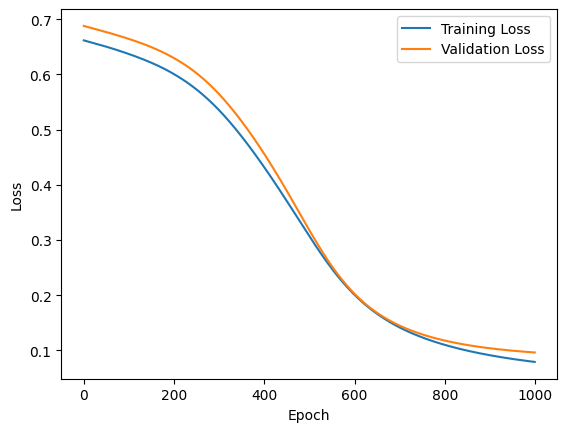

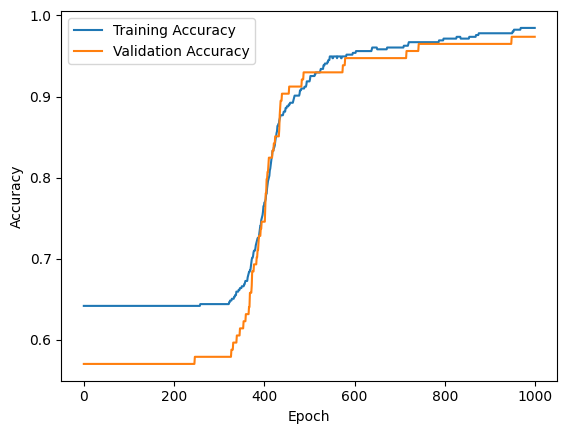


Accuracy = 0.9736842105263158
Precision = 1.0
Recall = 0.9387755102040817
F1 Score = 0.968421052631579 



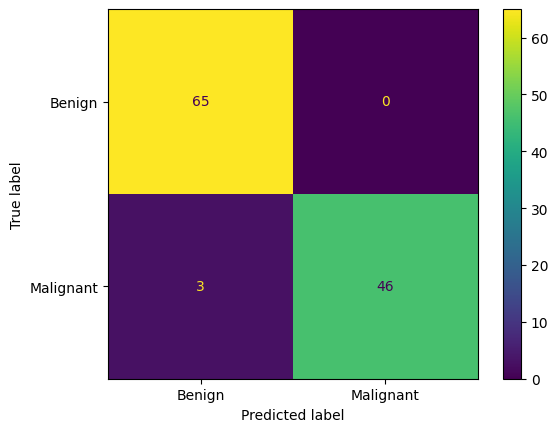

In [25]:
### Problem 2 ###

# Reading Dataset

df = pd.read_csv("/content/drive/MyDrive/ECGR_4105/Datasets/Cancer.csv")

# Initializing Variables

df = df.replace({"B": 0, "M": 1})
X = df.iloc[:, 2:32]
Y = df.iloc[:, 1]


# 80/20 Splitting

XT, XV, YT, YV = train_test_split(X, Y, train_size = 0.8, test_size = 0.2, random_state = 100)
YOG = YV.to_numpy()

# Standardization

scaler = StandardScaler()
XT = scaler.fit_transform(XT)
XV = scaler.transform(XV)

# Converting to Tensors

XT = torch.tensor(XT, dtype = torch.float32)
XV = torch.tensor(XV, dtype = torch.float32)
YT = torch.tensor(YT.values.reshape(-1, 1), dtype = torch.float32)
YV = torch.tensor(YV.values.reshape(-1, 1), dtype = torch.float32)

# Hyperparameters

n_epochs = 1000
learning_rate = 1e-2

# Model, Loss, and Optimizer Configuration

model = nn.Sequential(
    nn.Linear(30, 128),
    nn.ReLU(),
    nn.Linear(128, 32),
    nn.ReLU(),
    nn.Linear(32, 12),
    nn.ReLU(),
    nn.Linear(12, 1)
)

loss_fn = nn.BCEWithLogitsLoss()

optimizer = optim.SGD(model.parameters(), lr = learning_rate)

# Training Loop

training_losses = []
training_accuracies = []
validation_losses = []
validation_accuracies = []

for epoch in range(1, n_epochs + 1):
  prediction = model(XT)
  loss = loss_fn(prediction, YT)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  training_loss = loss.item()
  training_accuracy = ((torch.sigmoid(prediction) >= 0.5).float() == YT).float().mean().item()
  training_losses.append(training_loss)
  training_accuracies.append(training_accuracy)

  validation_loss = loss_fn(model(XV).detach(), YV).item()
  validation_accuracy = ((torch.sigmoid(model(XV).detach()) >= 0.5).float() == YV).float().mean().item()
  validation_losses.append(validation_loss)
  validation_accuracies.append(validation_accuracy)

  if epoch % 100 == 0:
    print("(Epoch = %d) Training Loss = %f, Training Accuracy = %f, Validation Loss = %f, Validation Accuracy = %f" % (epoch, float(training_loss), float(training_accuracy), float(validation_loss), float(validation_accuracy)))

# Plotting Graphs

print()
plt.figure()
plt.plot(training_losses, label = "Training Loss")
plt.plot(validation_losses, label = "Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

print()
plt.figure()
plt.plot(training_accuracies, label = "Training Accuracy")
plt.plot(validation_accuracies, label = "Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Scores

predictions = (torch.sigmoid(model(XV).detach()) >= 0.5).int().ravel().numpy()
YOG = YOG.astype(int)
print("\nAccuracy =", accuracy_score(YOG, predictions))
print("Precision =", precision_score(YOG, predictions))
print("Recall =", recall_score(YOG, predictions))
print("F1 Score =", f1_score(YOG, predictions), "\n")

# Confusion Matrix

matrix = confusion_matrix(YOG, predictions)
ConfusionMatrixDisplay(matrix, display_labels = ["Benign", "Malignant"]).plot()
plt.show()